# Практическая работа 2. Двумерные массивы и изображения
## Самостоятельные и контрольные задания

Параметры всех заданий берутся из паспортов A–G (файл `lab02_2d_arrays_images_variants_v1`) по номеру варианта `VARIANT`. Чтобы получить решение для другого варианта, поменяйте номер в ячейке ниже и выполните блокнот заново (*Run All*).

In [1]:
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

VARIANT = 1   # <-- номер вашего варианта (1..25)

In [2]:
# Паспорта A-G из файла вариантов (ключ -- номер варианта)
PASSPORTS = {"A":{"1":{"n_rows":4,"n_cols":6,"a":10,"b":-1},"2":{"n_rows":5,"n_cols":8,"a":20,"b":0},"3":{"n_rows":6,"n_cols":5,"a":50,"b":1},"4":{"n_rows":3,"n_cols":7,"a":10,"b":2},"5":{"n_rows":4,"n_cols":4,"a":20,"b":-2},"6":{"n_rows":5,"n_cols":6,"a":50,"b":-1},"7":{"n_rows":6,"n_cols":8,"a":10,"b":0},"8":{"n_rows":3,"n_cols":5,"a":20,"b":1},"9":{"n_rows":4,"n_cols":7,"a":50,"b":2},"10":{"n_rows":5,"n_cols":4,"a":10,"b":-2},"11":{"n_rows":6,"n_cols":6,"a":20,"b":-1},"12":{"n_rows":3,"n_cols":8,"a":50,"b":0},"13":{"n_rows":4,"n_cols":5,"a":10,"b":1},"14":{"n_rows":5,"n_cols":7,"a":20,"b":2},"15":{"n_rows":6,"n_cols":4,"a":50,"b":-2},"16":{"n_rows":3,"n_cols":6,"a":10,"b":-1},"17":{"n_rows":4,"n_cols":8,"a":20,"b":0},"18":{"n_rows":5,"n_cols":5,"a":50,"b":1},"19":{"n_rows":6,"n_cols":7,"a":10,"b":2},"20":{"n_rows":3,"n_cols":4,"a":20,"b":-2},"21":{"n_rows":4,"n_cols":6,"a":50,"b":-1},"22":{"n_rows":5,"n_cols":8,"a":10,"b":0},"23":{"n_rows":6,"n_cols":5,"a":20,"b":1},"24":{"n_rows":3,"n_cols":7,"a":50,"b":2},"25":{"n_rows":4,"n_cols":4,"a":10,"b":-2}},"B":{"1":{"H":180,"W":280,"bg":0},"2":{"H":200,"W":320,"bg":20},"3":{"H":220,"W":260,"bg":40},"4":{"H":240,"W":300,"bg":60},"5":{"H":180,"W":340,"bg":80},"6":{"H":200,"W":280,"bg":0},"7":{"H":220,"W":320,"bg":20},"8":{"H":240,"W":260,"bg":40},"9":{"H":180,"W":300,"bg":60},"10":{"H":200,"W":340,"bg":80},"11":{"H":220,"W":280,"bg":0},"12":{"H":240,"W":320,"bg":20},"13":{"H":180,"W":260,"bg":40},"14":{"H":200,"W":300,"bg":60},"15":{"H":220,"W":340,"bg":80},"16":{"H":240,"W":280,"bg":0},"17":{"H":180,"W":320,"bg":20},"18":{"H":200,"W":260,"bg":40},"19":{"H":220,"W":300,"bg":60},"20":{"H":240,"W":340,"bg":80},"21":{"H":180,"W":280,"bg":0},"22":{"H":200,"W":320,"bg":20},"23":{"H":220,"W":260,"bg":40},"24":{"H":240,"W":300,"bg":60},"25":{"H":180,"W":340,"bg":80}},"C":{"1":{"x":57,"y":49,"g":120},"2":{"x":94,"y":78,"g":160},"3":{"x":131,"y":107,"g":200},"4":{"x":168,"y":136,"g":230},"5":{"x":205,"y":25,"g":255},"6":{"x":242,"y":34,"g":120},"7":{"x":279,"y":43,"g":160},"8":{"x":96,"y":52,"g":200},"9":{"x":93,"y":141,"g":230},"10":{"x":90,"y":150,"g":255},"11":{"x":187,"y":159,"g":120},"12":{"x":184,"y":168,"g":160},"13":{"x":61,"y":117,"g":200},"14":{"x":278,"y":106,"g":230},"15":{"x":275,"y":95,"g":255},"16":{"x":132,"y":84,"g":120},"17":{"x":89,"y":93,"g":160},"18":{"x":26,"y":62,"g":200},"19":{"x":203,"y":31,"g":230},"20":{"x":160,"y":200,"g":255},"21":{"x":77,"y":69,"g":120},"22":{"x":274,"y":178,"g":160},"23":{"x":211,"y":147,"g":200},"24":{"x":128,"y":116,"g":230},"25":{"x":45,"y":45,"g":255}},"D":{"1":{"x1":23,"y1":21,"x2":248,"y2":146,"g":140,"thickness":2},"2":{"x1":36,"y1":32,"x2":271,"y2":147,"g":180,"thickness":3},"3":{"x1":49,"y1":43,"x2":194,"y2":203,"g":220,"thickness":4},"4":{"x1":62,"y1":54,"x2":217,"y2":209,"g":255,"thickness":1},"5":{"x1":75,"y1":65,"x2":325,"y2":160,"g":140,"thickness":2},"6":{"x1":88,"y1":10,"x2":233,"y2":171,"g":180,"thickness":3},"7":{"x1":101,"y1":14,"x2":266,"y2":182,"g":220,"thickness":4},"8":{"x1":28,"y1":18,"x2":239,"y2":193,"g":255,"thickness":1},"9":{"x1":27,"y1":49,"x2":282,"y2":129,"g":140,"thickness":2},"10":{"x1":27,"y1":54,"x2":325,"y2":145,"g":180,"thickness":3},"11":{"x1":60,"y1":58,"x2":218,"y2":161,"g":220,"thickness":4},"12":{"x1":60,"y1":62,"x2":261,"y2":177,"g":255,"thickness":1},"13":{"x1":93,"y1":33,"x2":219,"y2":143,"g":140,"thickness":2},"14":{"x1":92,"y1":32,"x2":272,"y2":169,"g":180,"thickness":3},"15":{"x1":92,"y1":29,"x2":325,"y2":195,"g":220,"thickness":4},"16":{"x1":32,"y1":26,"x2":203,"y2":221,"g":255,"thickness":1},"17":{"x1":19,"y1":17,"x2":256,"y2":157,"g":140,"thickness":2},"18":{"x1":72,"y1":10,"x2":199,"y2":143,"g":180,"thickness":3},"19":{"x1":57,"y1":73,"x2":262,"y2":174,"g":220,"thickness":4},"20":{"x1":44,"y1":70,"x2":325,"y2":205,"g":255,"thickness":1},"21":{"x1":97,"y1":61,"x2":258,"y2":126,"g":140,"thickness":2},"22":{"x1":84,"y1":54,"x2":251,"y2":167,"g":180,"thickness":3},"23":{"x1":51,"y1":44,"x2":244,"y2":153,"g":220,"thickness":4},"24":{"x1":22,"y1":34,"x2":252,"y2":189,"g":255,"thickness":1},"25":{"x1":109,"y1":45,"x2":325,"y2":140,"g":140,"thickness":2}},"E":{"1":{"x1":24,"y1":22,"x2":89,"y2":72,"g":130,"thickness":-1},"2":{"x1":33,"y1":29,"x2":103,"y2":89,"g":170,"thickness":1},"3":{"x1":42,"y1":36,"x2":117,"y2":76,"g":210,"thickness":2},"4":{"x1":51,"y1":43,"x2":131,"y2":93,"g":250,"thickness":3},"5":{"x1":60,"y1":50,"x2":145,"y2":110,"g":130,"thickness":4},"6":{"x1":69,"y1":57,"x2":129,"y2":97,"g":170,"thickness":-1},"7":{"x1":78,"y1":64,"x2":143,"y2":114,"g":210,"thickness":1},"8":{"x1":22,"y1":71,"x2":92,"y2":131,"g":250,"thickness":2},"9":{"x1":21,"y1":33,"x2":96,"y2":73,"g":130,"thickness":3},"10":{"x1":20,"y1":35,"x2":100,"y2":85,"g":170,"thickness":4},"11":{"x1":44,"y1":37,"x2":129,"y2":97,"g":210,"thickness":-1},"12":{"x1":43,"y1":39,"x2":103,"y2":79,"g":250,"thickness":1},"13":{"x1":67,"y1":16,"x2":132,"y2":66,"g":130,"thickness":2},"14":{"x1":66,"y1":63,"x2":136,"y2":123,"g":170,"thickness":3},"15":{"x1":65,"y1":65,"x2":140,"y2":105,"g":210,"thickness":4},"16":{"x1":19,"y1":67,"x2":99,"y2":117,"g":250,"thickness":-1},"17":{"x1":88,"y1":44,"x2":173,"y2":104,"g":130,"thickness":1},"18":{"x1":47,"y1":41,"x2":107,"y2":81,"g":170,"thickness":2},"19":{"x1":36,"y1":38,"x2":101,"y2":88,"g":210,"thickness":3},"20":{"x1":25,"y1":35,"x2":95,"y2":95,"g":250,"thickness":4},"21":{"x1":64,"y1":27,"x2":139,"y2":67,"g":130,"thickness":-1},"22":{"x1":53,"y1":19,"x2":133,"y2":69,"g":170,"thickness":1},"23":{"x1":27,"y1":66,"x2":112,"y2":126,"g":210,"thickness":2},"24":{"x1":81,"y1":63,"x2":141,"y2":103,"g":250,"thickness":3},"25":{"x1":70,"y1":55,"x2":135,"y2":105,"g":130,"thickness":4}},"F":{"1":{"x0":122,"y0":90,"R":21,"g":150,"thickness":-1},"2":{"x0":160,"y0":124,"R":24,"g":190,"thickness":1},"3":{"x0":148,"y0":98,"R":27,"g":225,"thickness":2},"4":{"x0":186,"y0":132,"R":30,"g":255,"thickness":3},"5":{"x0":134,"y0":66,"R":33,"g":150,"thickness":-1},"6":{"x0":122,"y0":100,"R":36,"g":190,"thickness":1},"7":{"x0":160,"y0":134,"R":39,"g":225,"thickness":2},"8":{"x0":148,"y0":108,"R":18,"g":255,"thickness":3},"9":{"x0":186,"y0":102,"R":21,"g":150,"thickness":-1},"10":{"x0":134,"y0":76,"R":24,"g":190,"thickness":1},"11":{"x0":122,"y0":110,"R":27,"g":225,"thickness":2},"12":{"x0":160,"y0":144,"R":30,"g":255,"thickness":3},"13":{"x0":148,"y0":78,"R":33,"g":150,"thickness":-1},"14":{"x0":186,"y0":112,"R":36,"g":190,"thickness":1},"15":{"x0":134,"y0":86,"R":39,"g":225,"thickness":2},"16":{"x0":122,"y0":120,"R":18,"g":255,"thickness":3},"17":{"x0":160,"y0":114,"R":21,"g":150,"thickness":-1},"18":{"x0":148,"y0":88,"R":24,"g":190,"thickness":1},"19":{"x0":186,"y0":122,"R":27,"g":225,"thickness":2},"20":{"x0":134,"y0":96,"R":30,"g":255,"thickness":3},"21":{"x0":122,"y0":90,"R":33,"g":150,"thickness":-1},"22":{"x0":160,"y0":124,"R":36,"g":190,"thickness":1},"23":{"x0":148,"y0":98,"R":39,"g":225,"thickness":2},"24":{"x0":186,"y0":132,"R":18,"g":255,"thickness":3},"25":{"x0":134,"y0":66,"R":21,"g":150,"thickness":-1}},"G":{"1":{"B":0,"G":0,"R":255},"2":{"B":0,"G":255,"R":0},"3":{"B":255,"G":0,"R":0},"4":{"B":0,"G":255,"R":255},"5":{"B":255,"G":255,"R":0},"6":{"B":255,"G":0,"R":255},"7":{"B":40,"G":120,"R":240},"8":{"B":220,"G":80,"R":30},"9":{"B":60,"G":200,"R":120},"10":{"B":180,"G":40,"R":200},"11":{"B":0,"G":0,"R":255},"12":{"B":0,"G":255,"R":0},"13":{"B":255,"G":0,"R":0},"14":{"B":0,"G":255,"R":255},"15":{"B":255,"G":255,"R":0},"16":{"B":255,"G":0,"R":255},"17":{"B":40,"G":120,"R":240},"18":{"B":220,"G":80,"R":30},"19":{"B":60,"G":200,"R":120},"20":{"B":180,"G":40,"R":200},"21":{"B":0,"G":0,"R":255},"22":{"B":0,"G":255,"R":0},"23":{"B":255,"G":0,"R":0},"24":{"B":0,"G":255,"R":255},"25":{"B":255,"G":255,"R":0}}}

def passport(letter):
    """Параметры паспорта для выбранного варианта."""
    return PASSPORTS[letter][str(VARIANT)] if str(VARIANT) in PASSPORTS[letter] else PASSPORTS[letter][VARIANT]

A, B, Cp, D, E, F, G = (passport(k) for k in "ABCDEFG")
for name, p in zip("ABCDEFG", (A, B, Cp, D, E, F, G)):
    print(f"Паспорт {name}:", p)

Паспорт A: {'n_rows': 4, 'n_cols': 6, 'a': 10, 'b': -1}
Паспорт B: {'H': 180, 'W': 280, 'bg': 0}
Паспорт C: {'x': 57, 'y': 49, 'g': 120}
Паспорт D: {'x1': 23, 'y1': 21, 'x2': 248, 'y2': 146, 'g': 140, 'thickness': 2}
Паспорт E: {'x1': 24, 'y1': 22, 'x2': 89, 'y2': 72, 'g': 130, 'thickness': -1}
Паспорт F: {'x0': 122, 'y0': 90, 'R': 21, 'g': 150, 'thickness': -1}
Паспорт G: {'B': 0, 'G': 0, 'R': 255}


In [3]:
def show(img, title="", color=False):
    """Показ в блокноте. Полутона: фиксированная шкала 0..255."""
    plt.figure(figsize=(6, 4))
    if color:
        plt.imshow(img)
    else:
        plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")
    plt.show()

> Примечание: в методичке для быстрого просмотра используется `Image.fromarray(img).show()` (внешнее окно). В блокноте с готовыми результатами используется `plt.imshow`; строка `Image.fromarray(img).show()` работает так же и может быть добавлена в любую ячейку.

# Самостоятельные задания

## С1. Двумерный массив по формуле
Паспорт A: $m_{r,c}=ar+c+b$.

In [4]:
n_rows, n_cols, a, b = A["n_rows"], A["n_cols"], A["a"], A["b"]
m = np.zeros((n_rows, n_cols), dtype=int)
for r in range(n_rows):
    for c in range(n_cols):
        m[r, c] = a * r + c + b

print(m)
print("shape =", m.shape)
print(f"m[0, 0] = {m[0, 0]}   (a*0+0+b = {b})")
print(f"m[1, 2] = {m[1, 2]}   (a*1+2+b = {a*1+2+b})")
print(f"m[{n_rows-1}, {n_cols-1}] = {m[-1, -1]}   (последний элемент)")

[[-1  0  1  2  3  4]
 [ 9 10 11 12 13 14]
 [19 20 21 22 23 24]
 [29 30 31 32 33 34]]
shape = (4, 6)
m[0, 0] = -1   (a*0+0+b = -1)
m[1, 2] = 11   (a*1+2+b = 11)
m[3, 5] = 34   (последний элемент)


## С2. Полутоновый холст и пиксель
Паспорта B и C. Пиксель $(x,y)$ записывается как `img[y, x]`.

shape = (180, 280)  dtype = uint8
img[y=49, x=57] = 120


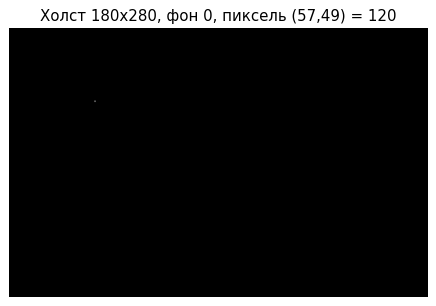

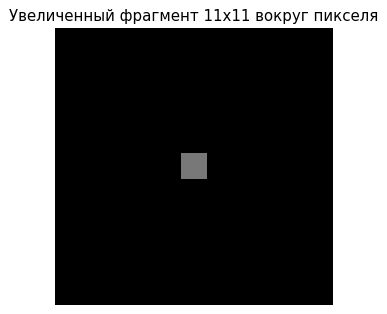

In [5]:
H, W, bg = B["H"], B["W"], B["bg"]
x, y, g = Cp["x"], Cp["y"], Cp["g"]

img = np.full((H, W), bg, dtype=np.uint8)
img[y, x] = g

print("shape =", img.shape, " dtype =", img.dtype)
print(f"img[y={y}, x={x}] = {img[y, x]}")
# один пиксель плохо виден -- заодно покажем увеличенный фрагмент вокруг него
show(img, f"Холст {H}x{W}, фон {bg}, пиксель ({x},{y}) = {g}")
y0, y1 = max(0, y - 5), min(H, y + 6)
x0, x1 = max(0, x - 5), min(W, x + 6)
show(img[y0:y1, x0:x1], "Увеличенный фрагмент 11x11 вокруг пикселя")

## С3. Прямоугольная область
Паспорта B и E: залитый прямоугольник (a) срезом NumPy, (б) `cv2.rectangle(..., -1)`.

Массивы совпадают: True
Максимальная разность = 0 ; различающихся пикселей = 0


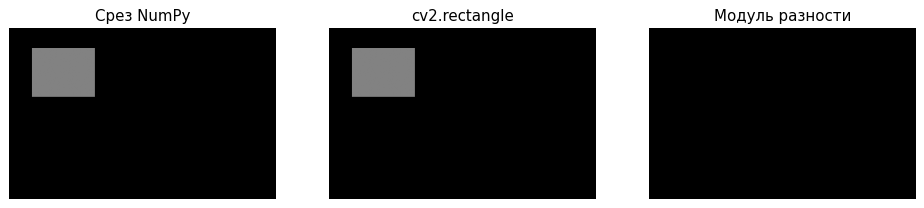

In [6]:
H, W, bg = B["H"], B["W"], B["bg"]
x1, y1, x2, y2, g = E["x1"], E["y1"], E["x2"], E["y2"], E["g"]

img_slice = np.full((H, W), bg, dtype=np.uint8)
img_slice[y1:y2 + 1, x1:x2 + 1] = g

img_cv = np.full((H, W), bg, dtype=np.uint8)
cv2.rectangle(img_cv, (x1, y1), (x2, y2), g, -1)

diff = cv2.absdiff(img_slice, img_cv)
print("Массивы совпадают:", np.array_equal(img_slice, img_cv))
print("Максимальная разность =", diff.max(), "; различающихся пикселей =", np.count_nonzero(diff))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for axis, im, t in zip(ax, (img_slice, img_cv, diff), ("Срез NumPy", "cv2.rectangle", "Модуль разности")):
    axis.imshow(im, cmap="gray", vmin=0, vmax=255); axis.set_title(t); axis.axis("off")
plt.show()

## С4. Отрезок и окружность
Паспорта B, D и F на одном изображении.

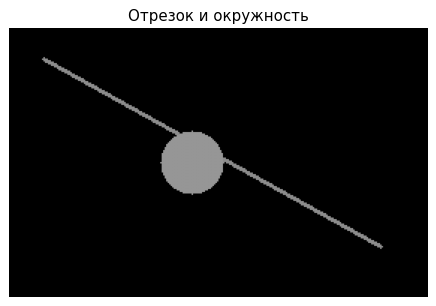

In [7]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)

cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])

show(img, "Отрезок и окружность")

## С5. Составное изображение
Паспорта B, C, D, E, F: точка, отрезок, прямоугольник, окружность.

**Связь координат и индексов:** $x=c$ (столбец), $y=r$ (строка), поэтому точка $(x,y)$ — это `img[y, x]`. Функции OpenCV (`line`, `rectangle`, `circle`) принимают точки в порядке `(x, y)`.

Точка: (x,y)=(57,49) -> img[49, 57] = 120


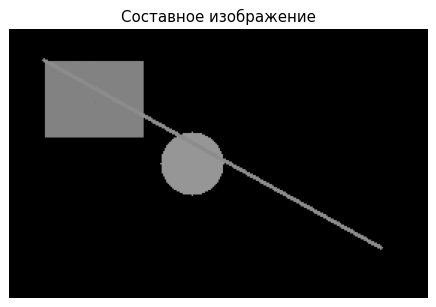

In [8]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)

cv2.rectangle(img, (E["x1"], E["y1"]), (E["x2"], E["y2"]), E["g"], E["thickness"])
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])
cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])
img[Cp["y"], Cp["x"]] = Cp["g"]          # точка: сначала y (строка), потом x (столбец)

print(f"Точка: (x,y)=({Cp['x']},{Cp['y']}) -> img[{Cp['y']}, {Cp['x']}] = {img[Cp['y'], Cp['x']]}")
show(img, "Составное изображение")

## С6. Цвет OpenCV и PIL
Паспорта B, E, G: цветной прямоугольник; цвет в OpenCV задан как $(B,G,R)$, для PIL/Matplotlib нужно преобразование в RGB.

shape = (180, 280, 3) ; цвет BGR = (0, 0, 255) -> RGB = (255, 0, 0)


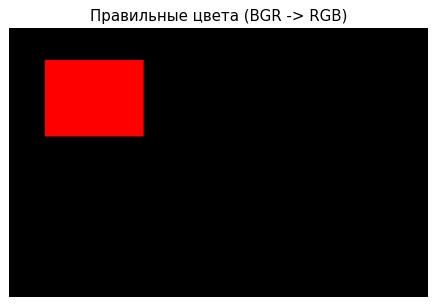

In [9]:
H, W = B["H"], B["W"]
color_bgr = (G["B"], G["G"], G["R"])

img_bgr = np.zeros((H, W, 3), dtype=np.uint8)
cv2.rectangle(img_bgr, (E["x1"], E["y1"]), (E["x2"], E["y2"]), color_bgr, E["thickness"])
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

print("shape =", img_bgr.shape, "; цвет BGR =", color_bgr, "-> RGB =", color_bgr[::-1])
# Image.fromarray(img_rgb).show()   # вариант для внешнего просмотрщика
show(img_rgb, "Правильные цвета (BGR -> RGB)", color=True)

## И1. Интегральная полутоновая сцена
Паспорта B, D, E, F: все размеры и координаты из таблиц; результат проверяется.

shape = (180, 280) dtype = uint8
Использованные яркости: [0, 130, 140, 150]


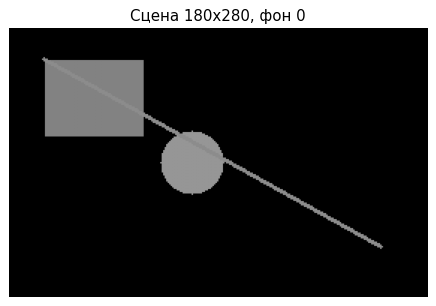

In [10]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)

cv2.rectangle(img, (E["x1"], E["y1"]), (E["x2"], E["y2"]), E["g"], E["thickness"])
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])
cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])

print("shape =", img.shape, "dtype =", img.dtype)
print("Использованные яркости:", sorted(int(v) for v in np.unique(img)))
show(img, f"Сцена {H}x{W}, фон {bg}")

## И2. Интегральная отладка
Паспорта B, C, G. Исходная программа содержала две ошибки:
1. индексы массива перепутаны с координатами: `img[x, y]` вместо `img[y, x]`;
2. BGR-массив передан в PIL/Matplotlib без преобразования в RGB.

Метка 5x5 вокруг (x,y)=(57,49); H=180, W=280
Центр метки при img[x, y]: (49, 57) (ожидалось (57, 49) )
Центр метки при img[y, x]: (57, 49)
Цвет BGR (0, 0, 255) -> RGB (255, 0, 0)


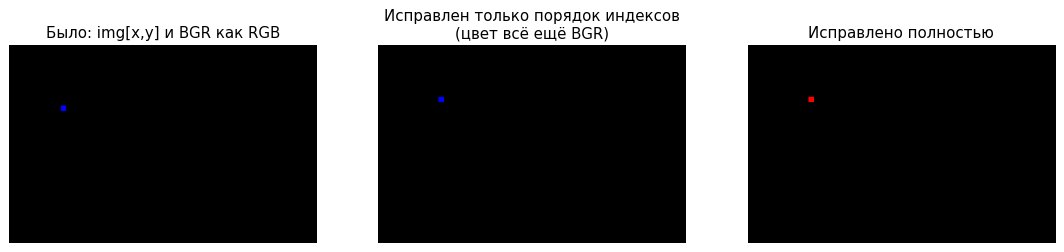

In [11]:
H, W = B["H"], B["W"]
x, y = Cp["x"], Cp["y"]
color_bgr = (G["B"], G["G"], G["R"])

def make_marker(wrong_index):
    img = np.zeros((H, W, 3), dtype=np.uint8)
    try:
        if wrong_index:
            img[x - 2:x + 3, y - 2:y + 3] = color_bgr     # ОШИБКА 1: [x, y]
        else:
            img[y - 2:y + 3, x - 2:x + 3] = color_bgr     # верно: [y, x]
    except IndexError as e:
        print("IndexError:", e)
    return img

bad = make_marker(True)
good = make_marker(False)

print(f"Метка 5x5 вокруг (x,y)=({x},{y}); H={H}, W={W}")
def center(im):
    yy, xx = np.nonzero(im.any(axis=2)); return (int(xx.mean()), int(yy.mean())) if len(xx) else None
print("Центр метки при img[x, y]:", center(bad), "(ожидалось", (x, y), ")")
print("Центр метки при img[y, x]:", center(good))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(bad);                                 ax[0].set_title("Было: img[x,y] и BGR как RGB")
ax[1].imshow(good);                                ax[1].set_title("Исправлен только порядок индексов\n(цвет всё ещё BGR)")
ax[2].imshow(cv2.cvtColor(good, cv2.COLOR_BGR2RGB)); ax[2].set_title("Исправлено полностью")
for a_ in ax: a_.axis("off")
plt.show()
print("Цвет BGR", color_bgr, "-> RGB", color_bgr[::-1])

# Контрольные задания

## К1. Форма и индексация
Паспорт A.

In [12]:
n_rows, n_cols, a, b = A["n_rows"], A["n_cols"], A["a"], A["b"]
r_idx, c_idx = np.indices((n_rows, n_cols))
m = a * r_idx + c_idx + b            # та же формула без циклов

print(m)
print("shape =", m.shape, "-> n_rows =", m.shape[0], ", n_cols =", m.shape[1])
for r, c in [(0, 0), (1, 2), (n_rows - 1, n_cols - 1)]:
    print(f"m[{r}, {c}] = {m[r, c]}   (= {a}*{r} + {c} + {b})")

[[-1  0  1  2  3  4]
 [ 9 10 11 12 13 14]
 [19 20 21 22 23 24]
 [29 30 31 32 33 34]]
shape = (4, 6) -> n_rows = 4 , n_cols = 6
m[0, 0] = -1   (= 10*0 + 0 + -1)
m[1, 2] = 11   (= 10*1 + 2 + -1)
m[3, 5] = 34   (= 10*3 + 5 + -1)


## К2. Ошибка индексации
Паспорта B и C. Найти и исправить `img[x, y]`.

In [13]:
H, W, bg = B["H"], B["W"], B["bg"]
x, y, g = Cp["x"], Cp["y"], Cp["g"]
img = np.full((H, W), bg, dtype=np.uint8)

# Ошибочный код:  img[x, y] = g
try:
    img[x, y] = g
    print(f"img[x={x}, y={y}] выполнилось без ошибки, но пиксель поставлен НЕ в ту точку: строка {x}, столбец {y}")
except IndexError as e:
    print(f"img[x, y] -> IndexError: {e}")
    print(f"Причина: x={x} используется как индекс строки, а строк только H={H}.")

# Исправление:
img = np.full((H, W), bg, dtype=np.uint8)
img[y, x] = g
print(f"Исправлено: img[y, x] = img[{y}, {x}] = {img[y, x]}")

img[x=57, y=49] выполнилось без ошибки, но пиксель поставлен НЕ в ту точку: строка 57, столбец 49
Исправлено: img[y, x] = img[49, 57] = 120


## К3. Полутоновое изображение
Паспорт B.

shape = (180, 280) (H, W) = (180, 280)
dtype = uint8 ; min = 0 ; max = 0


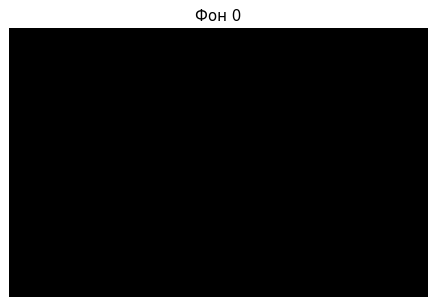

In [14]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
print("shape =", img.shape, "(H, W) =", (H, W))
print("dtype =", img.dtype, "; min =", img.min(), "; max =", img.max())
show(img, f"Фон {bg}")

## К4. Пиксель по координатам
Паспорта B и C. Первый индекс — строка $=y$, второй — столбец $=x$.

Точка (x,y)=(57,49) -> img[49, 57] = 120; строка=49, столбец=57
Всего пикселей, отличных от фона: 1


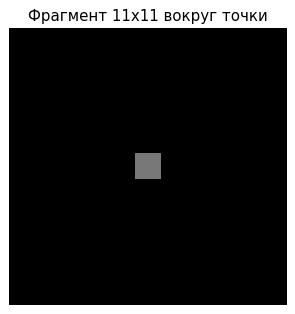

In [15]:
H, W, bg = B["H"], B["W"], B["bg"]
x, y, g = Cp["x"], Cp["y"], Cp["g"]
img = np.full((H, W), bg, dtype=np.uint8)
img[y, x] = g
print(f"Точка (x,y)=({x},{y}) -> img[{y}, {x}] = {img[y, x]}; строка={y}, столбец={x}")
print("Всего пикселей, отличных от фона:", np.count_nonzero(img != bg))
y0, y1, x0, x1 = max(0, y - 5), min(H, y + 6), max(0, x - 5), min(W, x + 6)
show(img[y0:y1, x0:x1], "Фрагмент 11x11 вокруг точки")

## К5. Отрезок
Паспорта B и D.

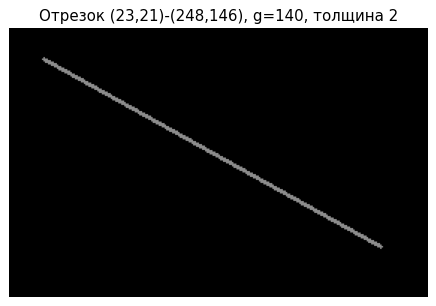

In [16]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])
show(img, f"Отрезок ({D['x1']},{D['y1']})-({D['x2']},{D['y2']}), g={D['g']}, толщина {D['thickness']}")

## К6. Прямоугольник
Паспорта B и E (`thickness=-1` — заливка).

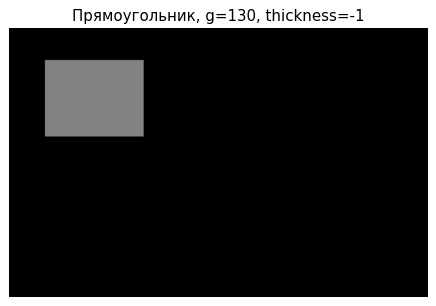

In [17]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
cv2.rectangle(img, (E["x1"], E["y1"]), (E["x2"], E["y2"]), E["g"], E["thickness"])
show(img, f"Прямоугольник, g={E['g']}, thickness={E['thickness']}")

## К7. Окружность
Паспорта B и F.

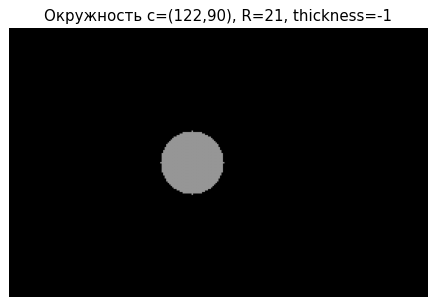

In [18]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])
show(img, f"Окружность c=({F['x0']},{F['y0']}), R={F['R']}, thickness={F['thickness']}")

## К8. Срез или OpenCV
Паспорта B и E: одна область двумя способами.

Совпадают: True ; max разность = 0
Площадь области (пикселей): 3366 ; ожидаемо: 3366


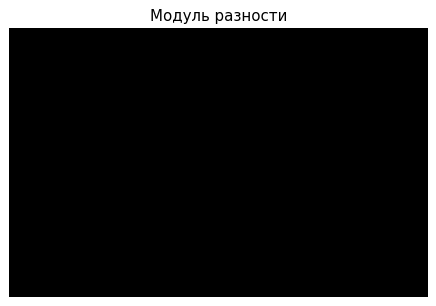

In [19]:
H, W, bg = B["H"], B["W"], B["bg"]
x1, y1, x2, y2, g = E["x1"], E["y1"], E["x2"], E["y2"], E["g"]

by_slice = np.full((H, W), bg, dtype=np.uint8)
by_slice[y1:y2 + 1, x1:x2 + 1] = g

by_cv = np.full((H, W), bg, dtype=np.uint8)
cv2.rectangle(by_cv, (x1, y1), (x2, y2), g, -1)

diff = cv2.absdiff(by_slice, by_cv)
print("Совпадают:", np.array_equal(by_slice, by_cv), "; max разность =", diff.max())
print("Площадь области (пикселей):", np.count_nonzero(by_slice == g) if g != bg else "-",
      "; ожидаемо:", (x2 - x1 + 1) * (y2 - y1 + 1))
show(diff, "Модуль разности")

## К9. Составная сцена
Паспорта B, D, E, F.

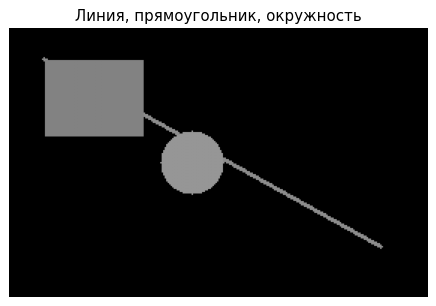

In [20]:
H, W, bg = B["H"], B["W"], B["bg"]
img = np.full((H, W), bg, dtype=np.uint8)
cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])
cv2.rectangle(img, (E["x1"], E["y1"]), (E["x2"], E["y2"]), E["g"], E["thickness"])
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])
show(img, "Линия, прямоугольник, окружность")

## К10. Проверка геометрии
Паспорта B, E, F: помещается ли фигура полностью в изображение. Допустимые координаты: $0\le x\le W-1$, $0\le y\le H-1$.

In [21]:
H, W = B["H"], B["W"]

# Прямоугольник: все четыре угла внутри изображения
xs, ys = (E["x1"], E["x2"]), (E["y1"], E["y2"])
rect_ok = 0 <= min(xs) and max(xs) <= W - 1 and 0 <= min(ys) and max(ys) <= H - 1
print(f"Прямоугольник: x in [{min(xs)}, {max(xs)}], y in [{min(ys)}, {max(ys)}], допустимо x<={W-1}, y<={H-1} -> {'помещается' if rect_ok else 'НЕ помещается'}")

# Окружность: крайние точки центр +- R
x0, y0, R = F["x0"], F["y0"], F["R"]
left, right, top, bottom = x0 - R, x0 + R, y0 - R, y0 + R
circ_ok = left >= 0 and right <= W - 1 and top >= 0 and bottom <= H - 1
print(f"Окружность: x in [{left}, {right}], y in [{top}, {bottom}] -> {'помещается' if circ_ok else 'НЕ помещается'}")

# Отдельная проверка по массиву: рисуем фигуру на пустом холсте с запасом и сравниваем яркость
pad = 100
big = np.zeros((H + 2 * pad, W + 2 * pad), dtype=np.uint8)
cv2.circle(big, (x0 + pad, y0 + pad), R, 255, 1)
inside = np.count_nonzero(big[pad:pad + H, pad:pad + W]); total = np.count_nonzero(big)
print(f"Проверка рисованием: пикселей окружности внутри кадра {inside} из {total}")

Прямоугольник: x in [24, 89], y in [22, 72], допустимо x<=279, y<=179 -> помещается
Окружность: x in [101, 143], y in [69, 111] -> помещается
Проверка рисованием: пикселей окружности внутри кадра 116 из 116


## К11. Цвет BGR/RGB
Паспорта B, E, G.

OpenCV (B,G,R) = (0, 0, 255) ; для PIL/Matplotlib (R,G,B) = (255, 0, 0)


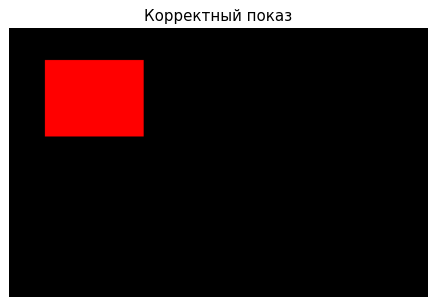

In [22]:
H, W = B["H"], B["W"]
color_bgr = (G["B"], G["G"], G["R"])
img_bgr = np.zeros((H, W, 3), dtype=np.uint8)
cv2.rectangle(img_bgr, (E["x1"], E["y1"]), (E["x2"], E["y2"]), color_bgr, E["thickness"])

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
print("OpenCV (B,G,R) =", color_bgr, "; для PIL/Matplotlib (R,G,B) =", tuple(int(v) for v in img_rgb[E['y1'], E['x1']]))
show(img_rgb, "Корректный показ", color=True)

## К12. Отладка цвета
Паспорта B, F, G. Причина неправильного цвета: массив в порядке BGR показан как RGB (красный и синий каналы поменялись местами).

Задан (B,G,R) = (0, 0, 255) ; без конвертации он читается как (R,G,B) = (0, 0, 255) -- красный и синий каналы перепутаны.
После cv2.cvtColor(BGR2RGB): (R,G,B) = (255, 0, 0)


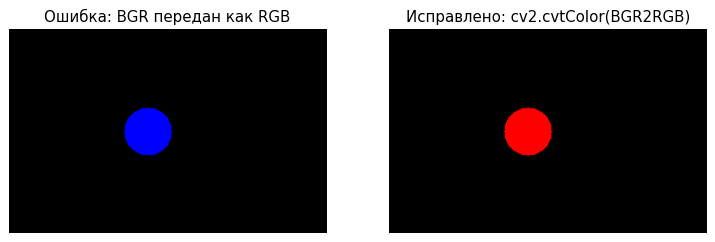

In [23]:
H, W = B["H"], B["W"]
color_bgr = (G["B"], G["G"], G["R"])
img_bgr = np.zeros((H, W, 3), dtype=np.uint8)
cv2.circle(img_bgr, (F["x0"], F["y0"]), F["R"], color_bgr, F["thickness"])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(img_bgr);                                  ax[0].set_title("Ошибка: BGR передан как RGB")
ax[1].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); ax[1].set_title("Исправлено: cv2.cvtColor(BGR2RGB)")
for a_ in ax: a_.axis("off")
plt.show()
print("Задан (B,G,R) =", color_bgr, "; без конвертации он читается как (R,G,B) =", color_bgr, "-- красный и синий каналы перепутаны.")
print("После cv2.cvtColor(BGR2RGB): (R,G,B) =", color_bgr[::-1])